<a href="https://colab.research.google.com/github/Perez-Alvaro/uber-lyft-dataset/blob/main/Contenido%20Entrega%203%20mejoras/2_Presentacion_Colab/Presentacion_Entrega3_Grupo11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# ¿Cuánto cuesta un viaje y cuándo hay recargo?
## Entrega 3 · Modelado y análisis de resultados

**Uber y Lyft en Boston, Massachusetts** · Grupo 11 · Ciencia de Datos 5K1 · UTN FRC · 30 de octubre de 2026

Álvaro Pérez · Juan Ignacio Cremona · Ignacio Gil · Federico Gon · Sofía Medina · Facundo Dagnino Dailly

---

**Recorrido**

1. De dónde venimos
2. Cómo evaluamos
3. Objetivo 1 · precio
4. Objetivo 2 · recargo: el problema de la accuracy
5. Parámetros de los modelos de recargo
6. Balanceo de clases
7. Modelos finales
8. Qué aprendieron los modelos
9. Por qué validar por fecha
10. Perfiles de rutas (K-Means)
11. Hipótesis y conclusiones

> **Para presentar:** *Entorno de ejecución → Ejecutar todo* (tarda menos de 30 segundos). El código está oculto: cada celda muestra solo su resultado. Doble clic en el título de una celda para ver el código.

In [1]:
# @title Preparación: cargar los resultados del repositorio { display-mode: "form" }
import json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

CARPETA = "Contenido Entrega 3 mejoras"

def buscar_raiz():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "6_Resultados" / "metricas.json").exists():
            return base
        if (base / CARPETA / "6_Resultados" / "metricas.json").exists():
            return base / CARPETA
    return None

RAIZ = buscar_raiz()
if RAIZ is None:  # en Colab: se descarga el repositorio una sola vez
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/Perez-Alvaro/uber-lyft-dataset.git"], check=True)
    RAIZ = Path("uber-lyft-dataset") / CARPETA

GRAF, RES, DATOS = RAIZ / "5_Graficos", RAIZ / "6_Resultados", RAIZ / "4_Datasets"
M = json.loads((RES / "metricas.json").read_text(encoding="utf-8"))

def figura(nombre, ancho=1000):
    display(Image(filename=str(GRAF / nombre), width=ancho))

def tabla(df):
    display(df.style.hide(axis="index").set_properties(**{"text-align": "left"})
              .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("background", "#F2F2F2")]}]))

num = lambda x, d=3: f"{x:.{d}f}".replace(".", ",")
pct = lambda x, d=1: f"{100 * x:.{d}f}".replace(".", ",") + "%"
usd = lambda x: "USD " + num(x, 2)
print(f"Resultados cargados desde «{RAIZ.name}»")

Resultados cargados desde «Contenido Entrega 3 mejoras»


## 1 · De dónde venimos

**Pregunta del proyecto (Entrega 1):** ¿qué factores influyen en el precio de un viaje y qué tan bien podemos predecirlo?

**Entrega 2:** limpiamos 693.071 cotizaciones y quedaron dos objetivos:

| | Objetivo 1 | Objetivo 2 |
|---|---|---|
| Variable | `price` (USD) | `has_surge` (0/1) |
| Pregunta | ¿Cuánto cuesta el viaje? | ¿Este viaje tiene recargo? |
| Tipo | Regresión | Clasificación binaria |
| Datos | Uber + Lyft · 636.568 filas | Lyft sin Shared · 255.953 filas |

**Decisiones que traemos y respetamos:** partimos del dataset codificado · modelamos `log(price)` · `price` y `surge_multiplier` quedan fuera del modelo de recargo (fuga de datos) · validamos **agrupando por fecha**.

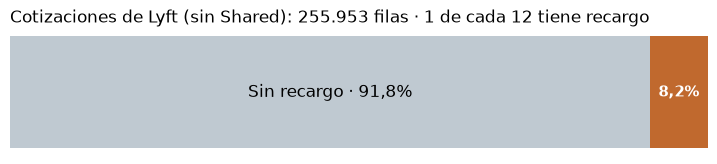

In [2]:
# @title Los datos de partida { display-mode: "form" }
surge = pd.read_csv(DATOS / "datasets modelado" / "dataset_modelado_surge.zip")
tasa = surge["has_surge"].mean()
fig, ax = plt.subplots(figsize=(9, 1.6))
ax.barh([0], [1 - tasa], color="#BFC9D1"); ax.barh([0], [tasa], left=[1 - tasa], color="#C0692E")
ax.text((1 - tasa) / 2, 0, f"Sin recargo · {pct(1 - tasa)}", ha="center", va="center", fontsize=12)
ax.text(1 - tasa / 2, 0, pct(tasa), ha="center", va="center", color="white", fontsize=11, weight="bold")
ax.set_xlim(0, 1); ax.axis("off")
ax.set_title(f"Cotizaciones de Lyft (sin Shared): {len(surge):,} filas · 1 de cada {round(1 / tasa)} tiene recargo".replace(",", "."),
             loc="left", fontsize=12)
plt.show()

## 2 · Cómo evaluamos: entrenar con el pasado, probar con días nuevos

En el 95,7% de los grupos (ruta, minuto) todos los productos comparten el recargo. Si separáramos las filas **al azar**, el modelo vería en el entrenamiento cotizaciones "gemelas" de las de prueba y las métricas saldrían infladas.

- **Prueba final:** entrenamiento con las 14 fechas hasta el 14/12/2018 → prueba con las 4 fechas del 15 al 18/12.
- **Elección de parámetros:** validación cruzada **GroupKFold** (5 folds) agrupando por fecha, solo dentro del entrenamiento.

| Partición | Fechas | Precio | Recargo | % con recargo |
|---|---|---|---|---|
| Entrenamiento | 25/11 al 14/12 | 488.074 | 196.558 | 8,16% |
| Prueba | 15/12 al 18/12 | 148.494 | 59.395 | 8,30% |

**Algoritmos:** Ridge y regresión logística (lineales) · árbol de decisión · random forest · K-Means (complementario).

## 3 · Objetivo 1 · ¿Cuánto cuesta el viaje?

Tres modelos sobre `log(price)`, cada uno **con y sin** `surge_multiplier`, comparados contra una línea base que solo conoce el producto.

In [3]:
# @title Parámetros elegidos (validación agrupada por fecha) { display-mode: "form" }
t = M["B_tuning"]
tabla(pd.DataFrame([
    ["Ridge", "alpha (regularización L2)", "0,01 a 1.000", str(t["Ridge"]["params"]["alpha"]), "Mínimo error de validación; con ~500 mil filas la regularización pesa poco"],
    ["Árbol de decisión", "max_depth · min_samples_leaf", "6 a 24 · 5 a 100",
     f'{t["Árbol de decisión"]["params"]["max_depth"]} · {t["Árbol de decisión"]["params"]["min_samples_leaf"]}', "Más profundo empieza a memorizar"],
    ["Random forest", "max_depth · min_samples_leaf", "12, 16, 24 · 2, 5, 20",
     f'{t["Random forest"]["params"]["max_depth"]} · {t["Random forest"]["params"]["min_samples_leaf"]}', "150 árboles, max_features 0,5"],
], columns=["Modelo", "Parámetros", "Valores probados", "Elegido", "Por qué"]))

Modelo,Parámetros,Valores probados,Elegido,Por qué
Ridge,alpha (regularización L2),"0,01 a 1.000",10,Mínimo error de validación; con ~500 mil filas la regularización pesa poco
Árbol de decisión,max_depth · min_samples_leaf,6 a 24 · 5 a 100,18 · 20,Más profundo empieza a memorizar
Random forest,max_depth · min_samples_leaf,"12, 16, 24 · 2, 5, 20",24 · 5,"150 árboles, max_features 0,5"


In [4]:
# @title Resultados en el período de prueba { display-mode: "form" }
filas = []
for r in M["B_regresion"]:
    filas.append([r["modelo"].replace("Línea base: mediana por producto", "Línea base (mediana por producto)"),
                  r["variante"], usd(r["mae"]), usd(r["rmse"]), pct(r["mape"]), pct(r["dentro_10pct"]), num(r["r2"])])
tabla(pd.DataFrame(filas, columns=["Modelo", "Variante", "MAE", "RMSE", "Error medio %", "Predicciones a ≤10% del real", "R²"]))

Modelo,Variante,MAE,RMSE,Error medio %,Predicciones a ≤10% del real,R²
Línea base (mediana por producto),-,"USD 3,04","USD 4,59","19,8%","34,1%","0,758"
Ridge,sin surge,"USD 1,62","USD 2,80","10,4%","62,1%","0,910"
Ridge,con surge,"USD 1,39","USD 2,06","9,6%","65,7%","0,951"
Árbol de decisión,sin surge,"USD 1,38","USD 2,58","9,1%","69,8%","0,924"
Árbol de decisión,con surge,"USD 1,09","USD 1,73","8,0%","73,6%","0,966"
Random forest,sin surge,"USD 1,33","USD 2,50","8,8%","71,1%","0,928"
Random forest,con surge,"USD 1,05","USD 1,67","7,7%","75,6%","0,968"


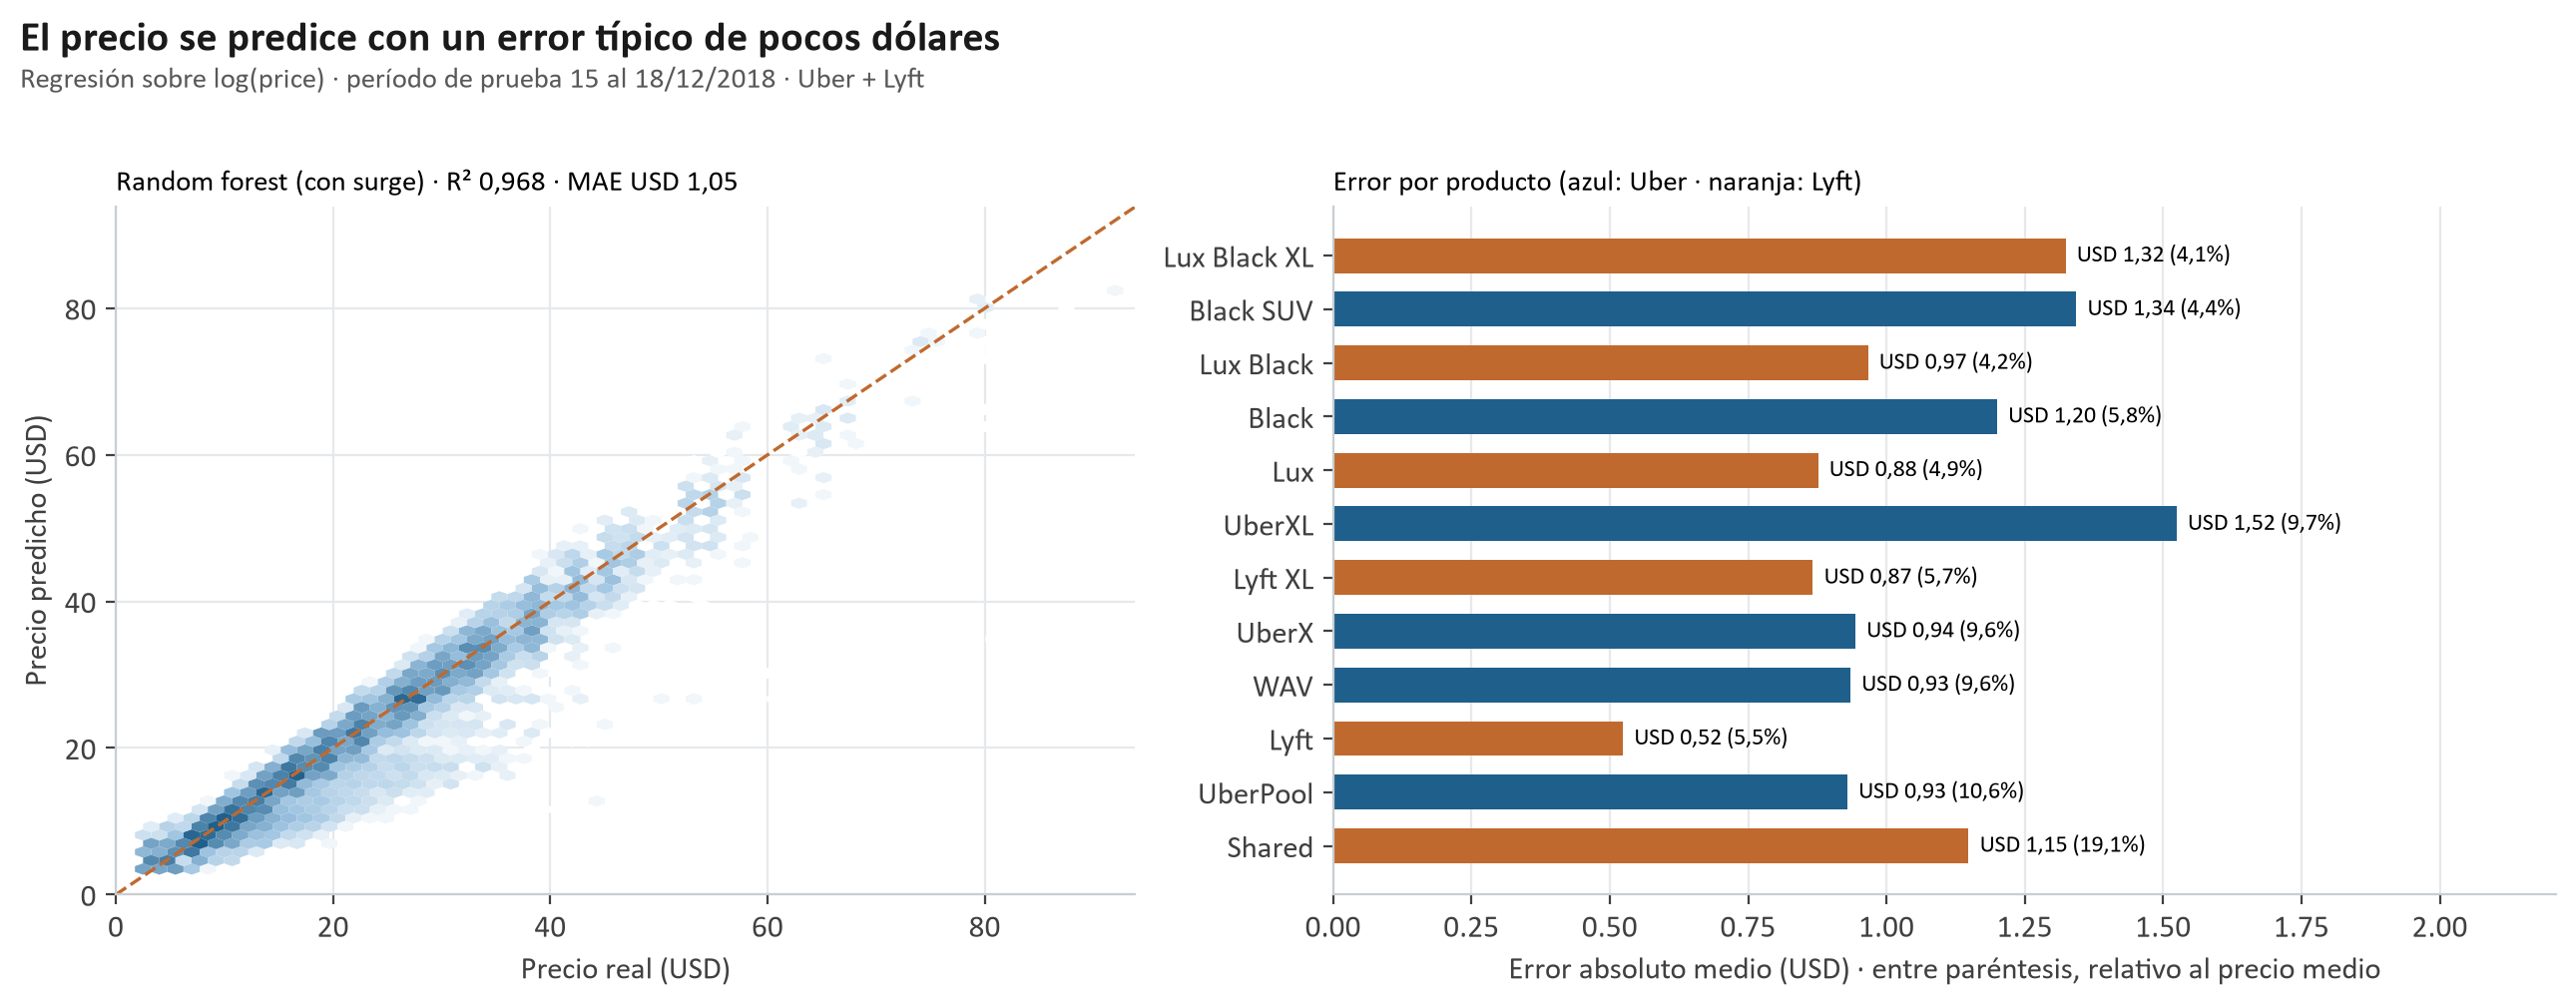

In [5]:
# @title Figura 1 · Real vs predicho y error por producto { display-mode: "form" }
figura("fig01_precio_real_vs_predicho.png")

**Lectura**

- El **random forest con surge** predice el precio con un error medio de **USD 1,05** (R² = 0,968): el **76%** de los viajes queda a menos de 10% de su precio real.
- Los árboles superan al modelo lineal: la tarifa crece por **escalones** y cada producto tiene su propia tarifa por milla.
- `surge_multiplier` reduce el error un 21%: ayuda, pero el precio ya es predecible sin él (R² = 0,928).

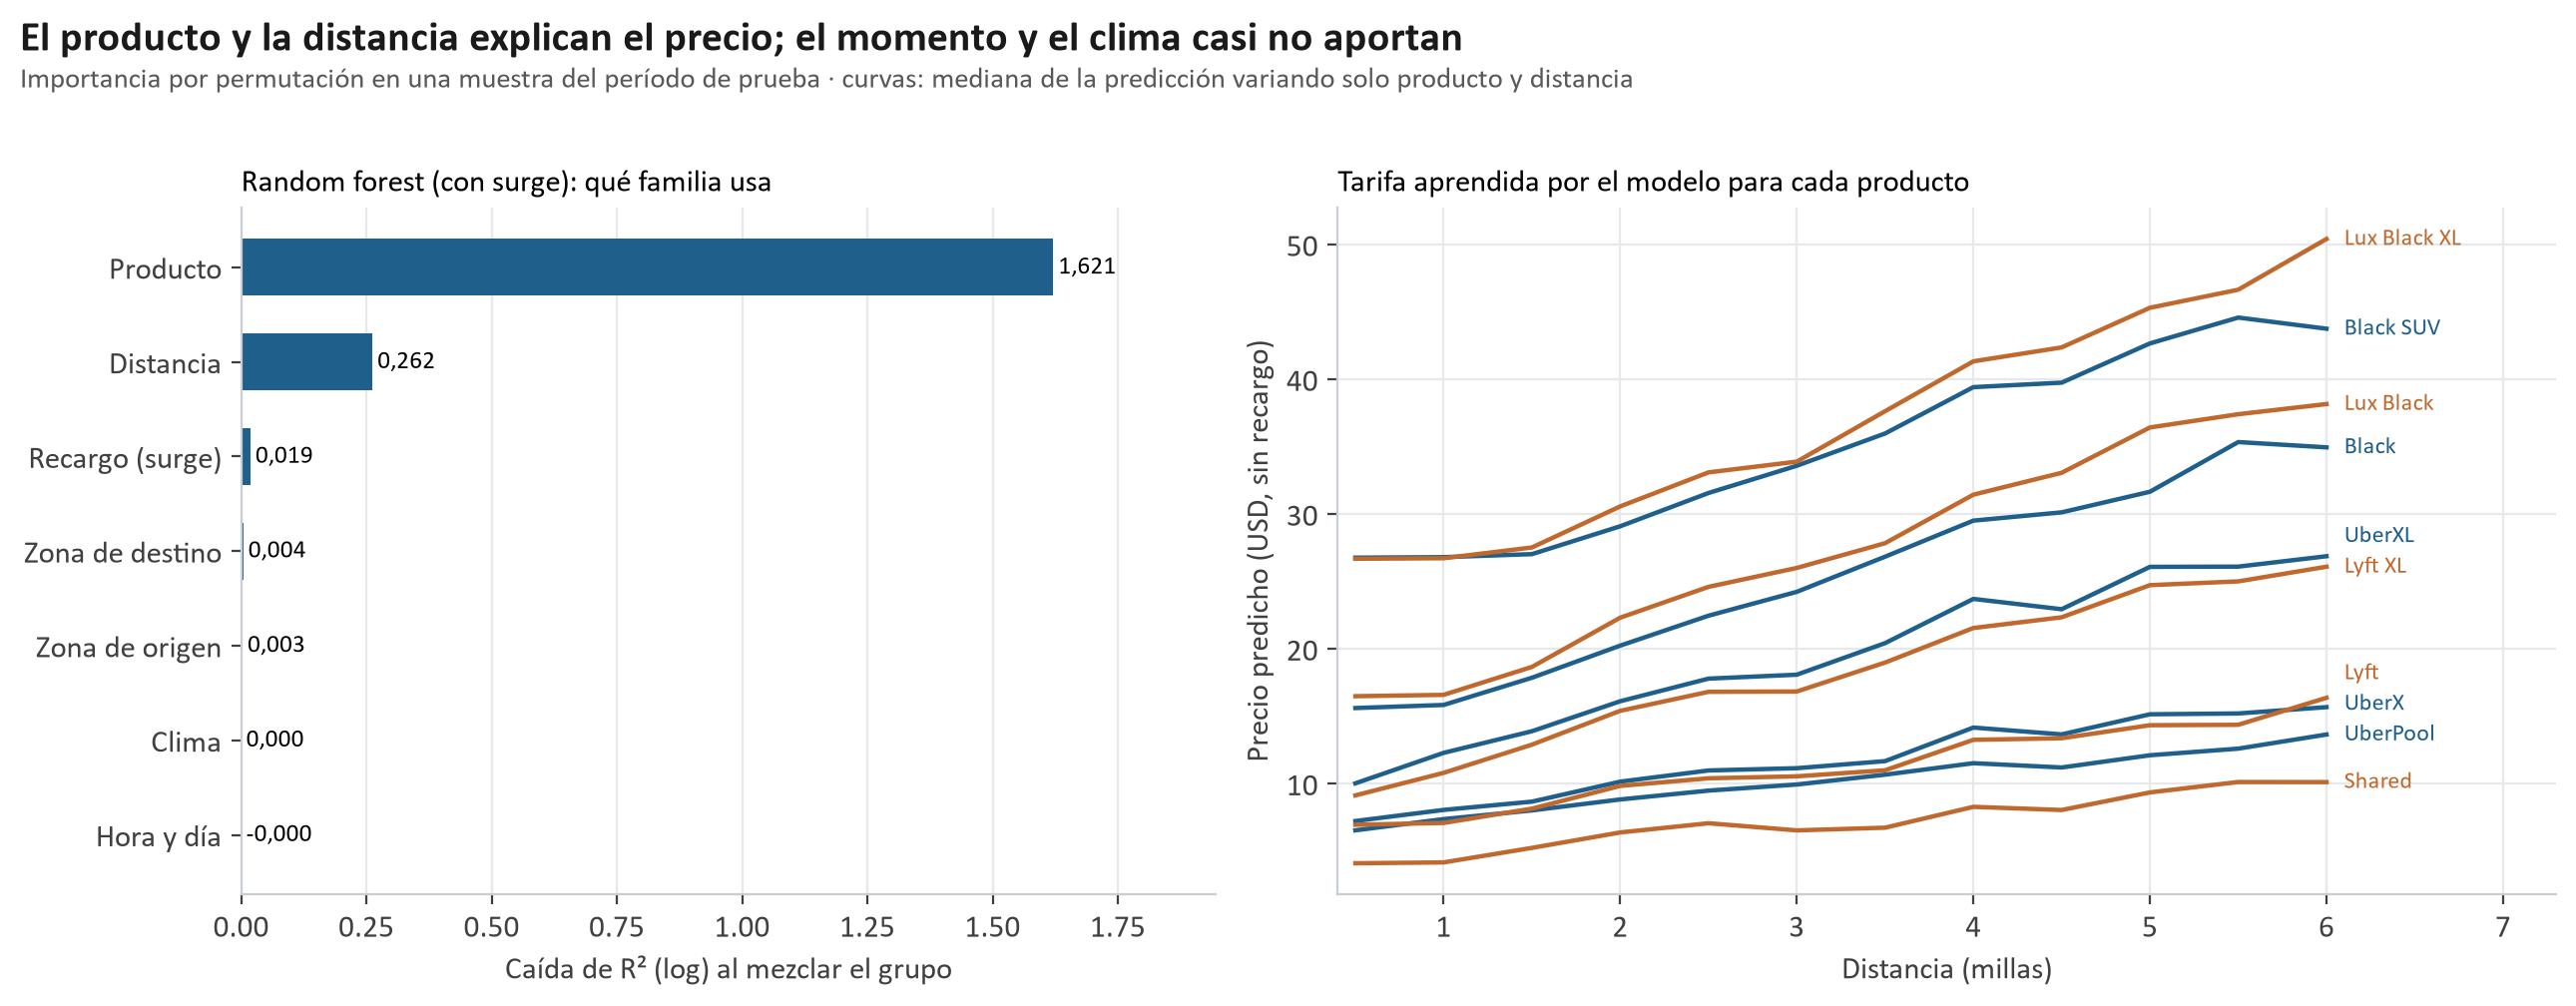

In [6]:
# @title Figura 2 · Qué usa el modelo y tarifas aprendidas { display-mode: "form" }
figura("fig02_precio_importancia_y_tarifas.png")

- **H1 confirmada:** el **producto** y la **distancia** explican casi todo; hora, día y clima no aportan nada.
- **H2 confirmada:** a igual distancia, Lyft es más barato en los económicos (Shared −30% vs UberPool, Lyft −5% vs UberX) y más caro en los Black (Lux Black +8%).

## 4 · Objetivo 2 · ¿Este viaje tiene recargo? El problema de la accuracy

La **accuracy (exactitud)** es la proporción de predicciones correctas:

$$\text{Accuracy} = \frac{VP + VN}{VP + VN + FP + FN}$$

Es la primera métrica que miramos, **pero siempre contra una línea base**. Con 8,2% de recargos, un "modelo" que dice siempre *sin recargo* ya acierta el **91,7%**… y no detecta ni un solo recargo. Por eso la acompañamos con la **accuracy balanceada** (promedio del acierto en cada clase: 50% = azar), recall, precisión, F1 y PR-AUC.

In [7]:
# @title Líneas base: lo que hay que superar { display-mode: "form" }
tabla(pd.DataFrame([[r["modelo"], pct(r["accuracy"]), pct(r["accuracy_balanceada"]), pct(r["recall"]), pct(r["precision"]), num(r["f1"]), num(r["pr_auc"])]
                     for r in M["A_lineas_base"]],
                    columns=["Línea base", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "F1", "PR-AUC"]))

Línea base,Accuracy,Accuracy balanceada,Recall,Precisión,F1,PR-AUC
Siempre 'sin recargo',"91,7%","50,0%","0,0%","0,0%","0,000","0,083"
Azar con la tasa real,"85,0%","50,1%","8,2%","8,4%","0,083","0,083"


### Demostración en vivo: el mismo árbol, sin balancear y con pesos de clase

Entrenamos el árbol de decisión final dos veces sobre las fechas de entrenamiento y lo evaluamos en los días de prueba.

Árbol,Accuracy,Accuracy balanceada,Recall,Precisión,Alertas emitidas
Sin balancear,"91,7%","50,0%","0,0%","0,0%",0
Con pesos de clase,"60,1%","63,0%","66,4%","12,9%",25.298


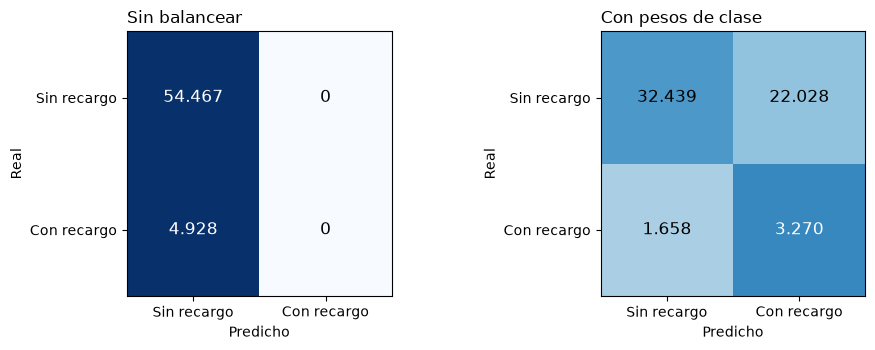

In [8]:
# @title Entrenar y comparar (≈10 segundos) { display-mode: "form" }
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, confusion_matrix

predictoras = [c for c in surge.columns if c not in ("id", "datetime_local", "fecha", "particion", "has_surge")]
tr, te = surge[surge["particion"] == "train"], surge[surge["particion"] == "test"]
params = M["A_tuning"]["Árbol de decisión"]["params"]
resultados, matrices = [], []
for etiqueta, pesos in [("Sin balancear", None), ("Con pesos de clase", "balanced")]:
    arbol = DecisionTreeClassifier(**params, class_weight=pesos, random_state=42).fit(tr[predictoras], tr["has_surge"])
    pred = arbol.predict(te[predictoras])
    resultados.append([etiqueta, pct(accuracy_score(te["has_surge"], pred)), pct(balanced_accuracy_score(te["has_surge"], pred)),
                       pct(recall_score(te["has_surge"], pred)), pct(precision_score(te["has_surge"], pred, zero_division=0)),
                       f'{int(pred.sum()):,}'.replace(",", ".")])
    matrices.append((etiqueta, confusion_matrix(te["has_surge"], pred)))
tabla(pd.DataFrame(resultados, columns=["Árbol", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "Alertas emitidas"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (etiqueta, cm) in zip(axes, matrices):
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] / cm[i].sum() > 0.6 else "black")
    ax.set_xticks([0, 1], ["Sin recargo", "Con recargo"]); ax.set_yticks([0, 1], ["Sin recargo", "Con recargo"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(etiqueta, loc="left")
plt.tight_layout(); plt.show()

**Lo que muestra la demo:** sin balancear, la accuracy es altísima porque el árbol responde siempre *sin recargo* (recall 0%). Con pesos de clase la accuracy **baja**, pero la accuracy balanceada **sube** y el modelo empieza a detectar recargos. Una accuracy alta no alcanza: hay que mirar qué clase está acertando.

## 5 · Parámetros de los modelos de recargo

In [9]:
# @title Valores elegidos con validación agrupada por fecha (métrica: PR-AUC) { display-mode: "form" }
t = M["A_tuning"]
tabla(pd.DataFrame([
    ["Regresión logística", "C (inverso de la regularización)", "0,0001 a 10", num(t["Regresión logística"]["params"]["C"]), "Regularización fuerte: señal débil, generaliza mejor entre fechas"],
    ["Árbol de decisión", "max_depth · min_samples_leaf · criterion", "3 a 40 · 20 a 500 · gini/entropy",
     f'{t["Árbol de decisión"]["params"]["max_depth"]} · {t["Árbol de decisión"]["params"]["min_samples_leaf"]} · gini', "Hojas grandes frenan el sobreajuste"],
    ["Random forest", "max_depth · min_samples_leaf", "10, 16, sin límite · 10 a 200",
     f'{t["Random forest"]["params"]["max_depth"]} · {t["Random forest"]["params"]["min_samples_leaf"]}', "150 árboles, max_features = raíz cuadrada"],
], columns=["Modelo", "Parámetros", "Valores probados", "Elegido", "Por qué"]))

Modelo,Parámetros,Valores probados,Elegido,Por qué
Regresión logística,C (inverso de la regularización),"0,0001 a 10","0,001","Regularización fuerte: señal débil, generaliza mejor entre fechas"
Árbol de decisión,max_depth · min_samples_leaf · criterion,3 a 40 · 20 a 500 · gini/entropy,20 · 500 · gini,Hojas grandes frenan el sobreajuste
Random forest,max_depth · min_samples_leaf,"10, 16, sin límite · 10 a 200",16 · 50,"150 árboles, max_features = raíz cuadrada"


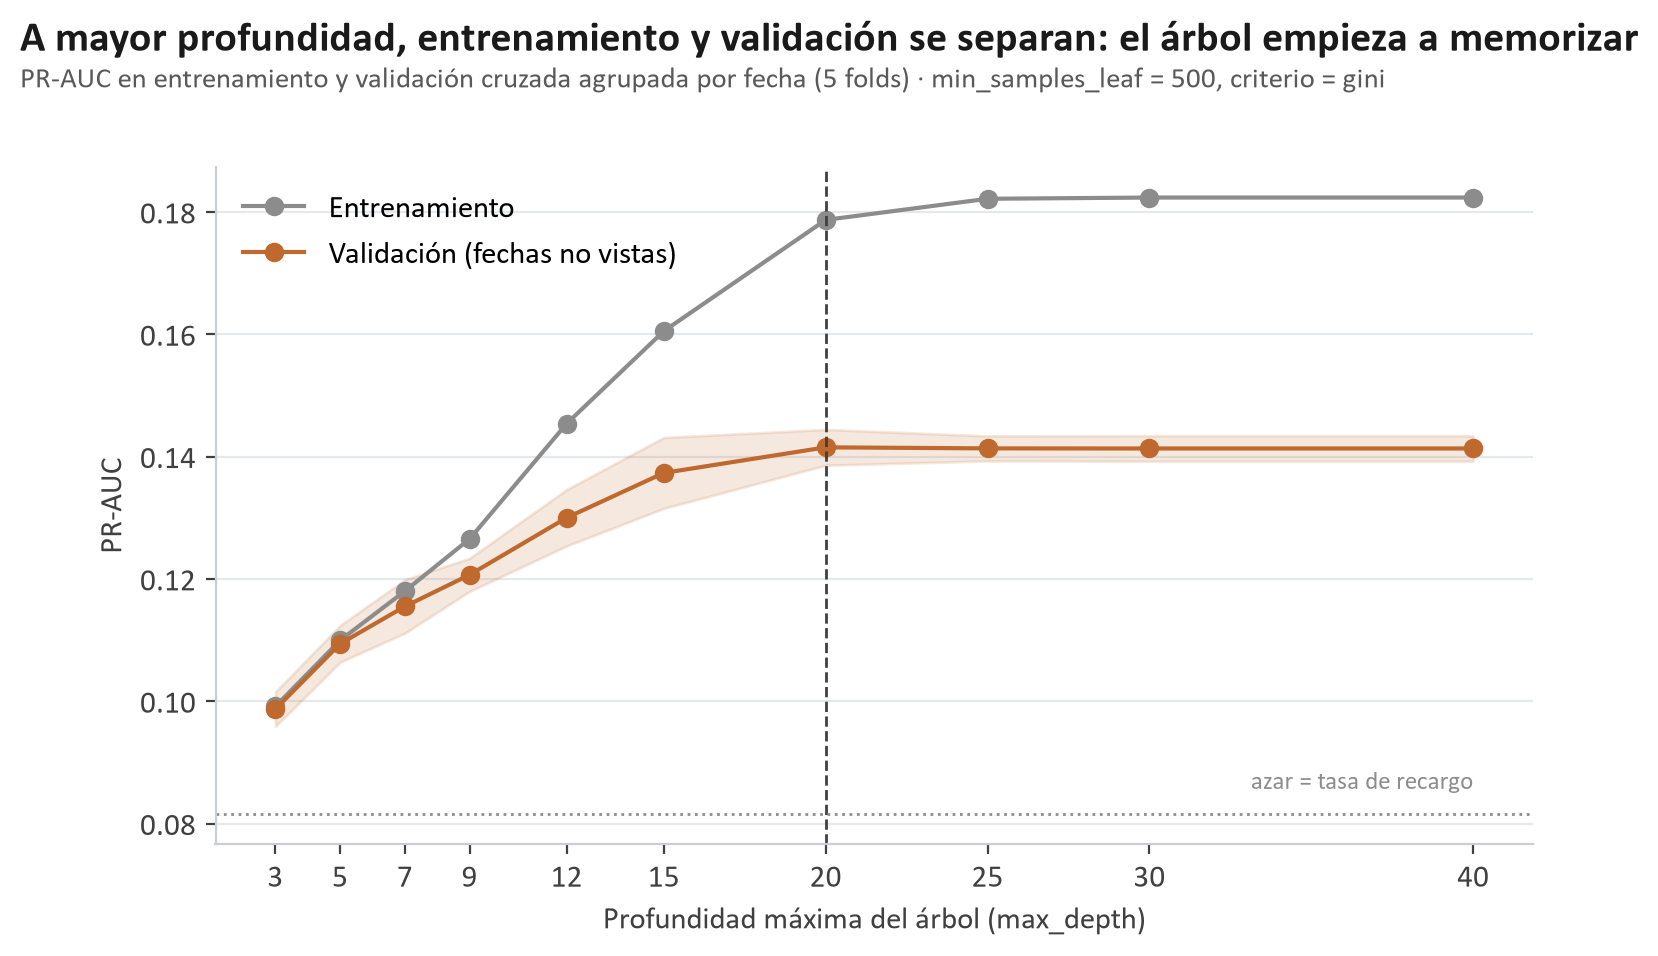

In [10]:
# @title Figura 3 · Sobreajuste del árbol según la profundidad { display-mode: "form" }
figura("fig03_recargo_validacion_profundidad.png", 800)

A partir de cierta profundidad el árbol sigue mejorando en entrenamiento pero **no en días nuevos**: está memorizando. Por eso elegimos el punto donde la validación deja de mejorar.

## 6 · Balanceo de clases: cuatro técnicas comparadas

El balanceo se aplica **solo al entrenamiento**; la prueba siempre conserva la proporción real (8,3%).

| Técnica | Qué hace | Filas de entrenamiento | % con recargo |
|---|---|---|---|
| Sin balanceo | Proporción real | 196.558 | 8,2% |
| Submuestreo (RUS) | Descarta al azar cotizaciones sin recargo | 32.094 | 50,0% |
| SMOTE | Crea recargos sintéticos interpolando vecinos | 361.022 | 50,0% |
| Pesos de clase | No cambia filas: un error en un recargo pesa 6,12 y en un no-recargo 0,54 | 196.558 | 8,2% |

Los datasets balanceados están en `4_Datasets/datasets balanceados/`.

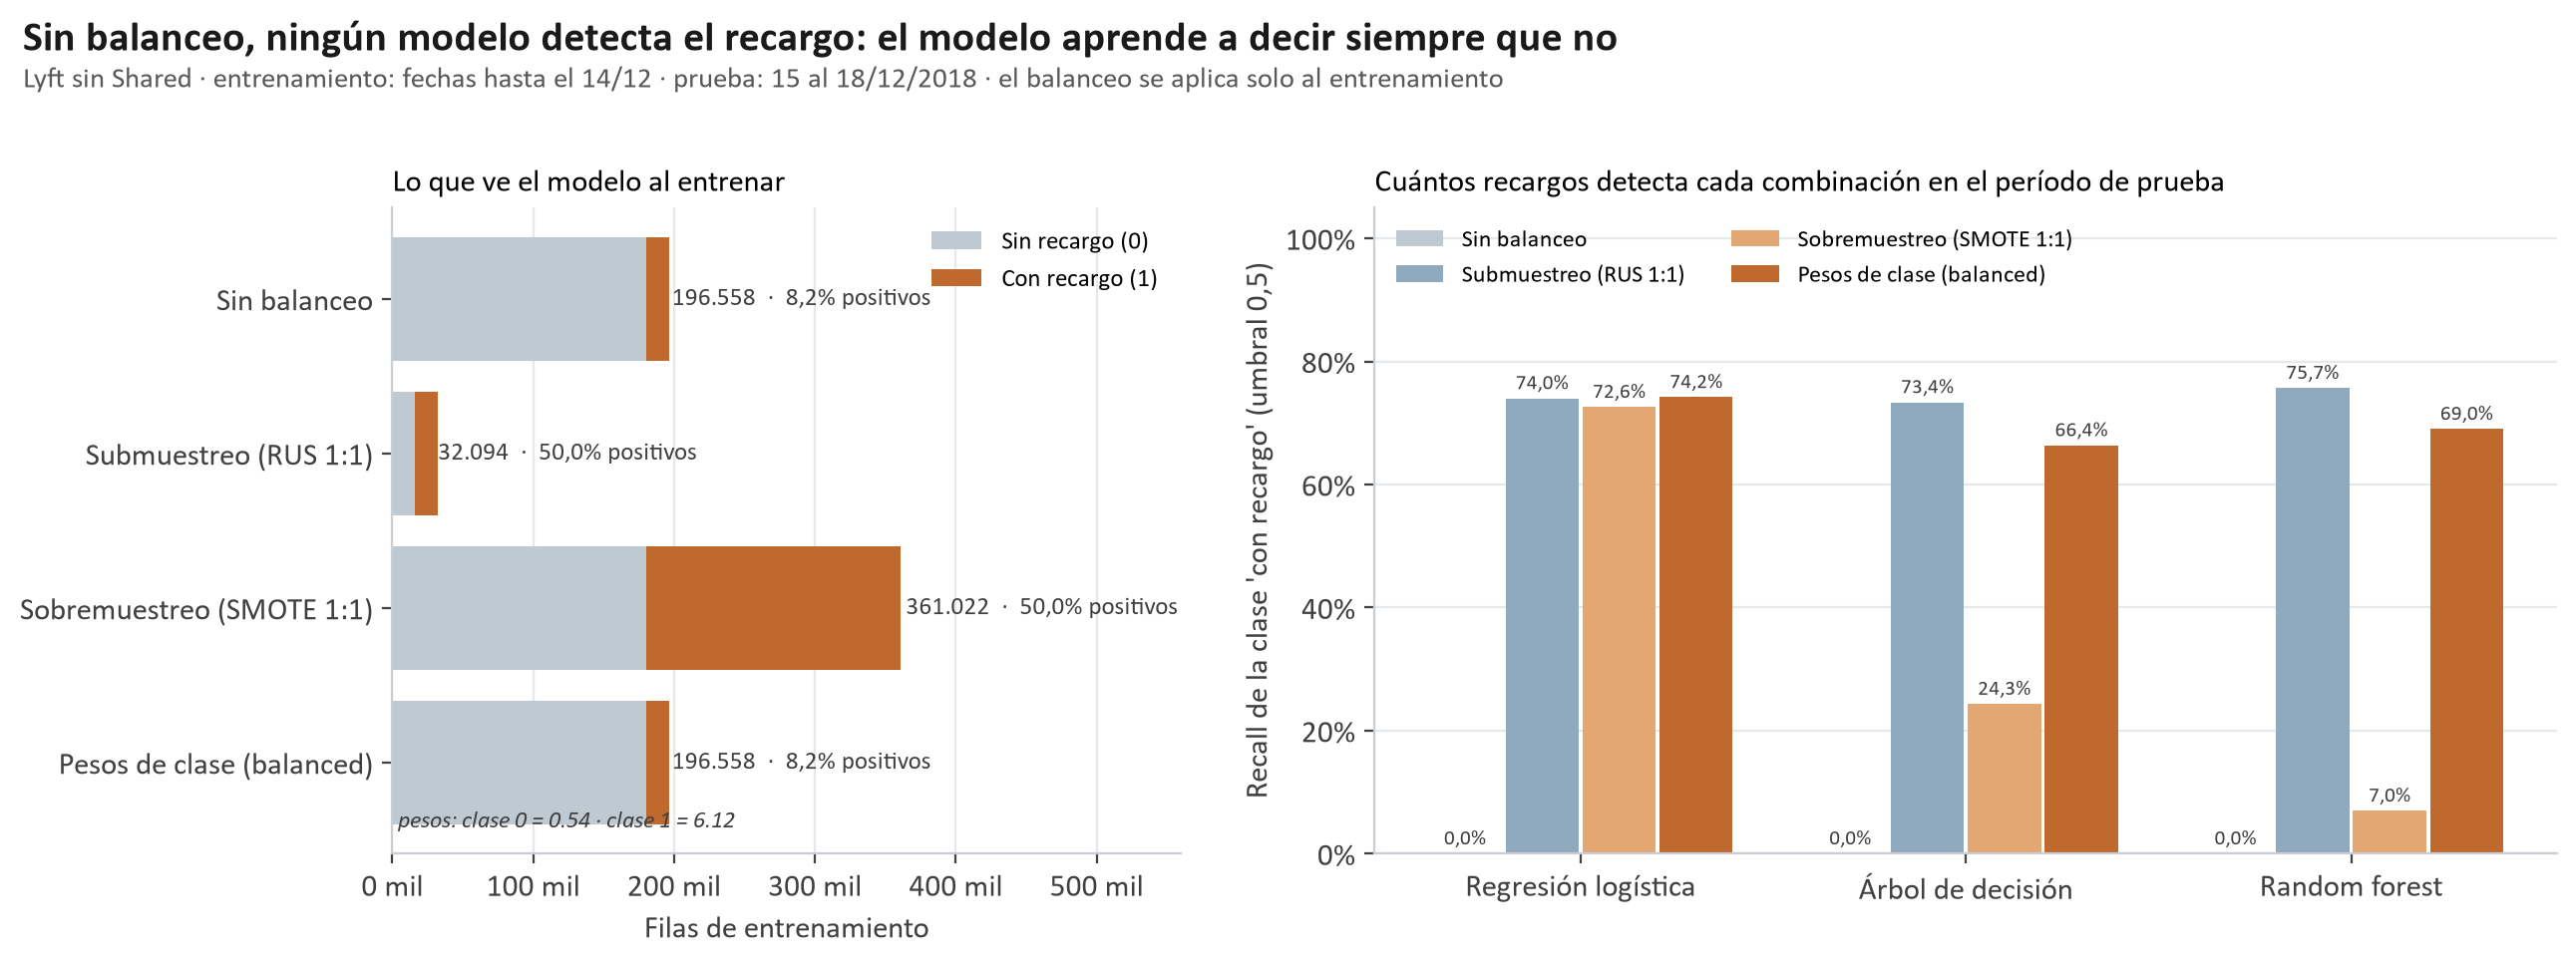

In [11]:
# @title Figura 4 · Distribución y recargos detectados { display-mode: "form" }
figura("fig04_recargo_balanceo.png")

In [12]:
# @title Resultados de cada combinación (umbral 0,5) { display-mode: "form" }
b = pd.read_csv(RES / "recargo_balanceo_test.csv")
tabla(pd.DataFrame({"Modelo": b["modelo"], "Técnica": b["tecnica"], "Accuracy": b["accuracy"].map(pct),
                    "Accuracy balanceada": b["accuracy_balanceada"].map(pct), "Recall": b["recall"].map(pct),
                    "Precisión": b["precision"].map(pct), "F1": b["f1"].map(num), "PR-AUC": b["pr_auc"].map(num)}))

Modelo,Técnica,Accuracy,Accuracy balanceada,Recall,Precisión,F1,PR-AUC
Regresión logística,Sin balanceo,"91,7%","50,0%","0,0%","0,0%","0,000","0,121"
Regresión logística,Submuestreo (RUS 1:1),"52,4%","62,2%","74,0%","11,9%","0,205","0,121"
Regresión logística,Sobremuestreo (SMOTE 1:1),"53,0%","61,9%","72,6%","11,9%","0,204","0,122"
Regresión logística,Pesos de clase (balanced),"52,1%","62,2%","74,2%","11,9%","0,205","0,122"
Árbol de decisión,Sin balanceo,"91,7%","50,0%","0,0%","0,0%","0,000","0,141"
Árbol de decisión,Submuestreo (RUS 1:1),"53,7%","62,6%","73,4%","12,1%","0,208","0,129"
Árbol de decisión,Sobremuestreo (SMOTE 1:1),"79,1%","54,2%","24,3%","12,1%","0,162","0,110"
Árbol de decisión,Pesos de clase (balanced),"60,1%","63,0%","66,4%","12,9%","0,216","0,142"
Random forest,Sin balanceo,"91,7%","50,0%","0,0%","0,0%","0,000","0,136"
Random forest,Submuestreo (RUS 1:1),"51,7%","62,6%","75,7%","11,9%","0,206","0,127"


**Lectura**

1. **Sin balanceo los tres modelos fallan igual:** accuracy 91,7%, recall 0%.
2. **Balancear no mejora el ranking, mueve el umbral:** el PR-AUC casi no cambia (árbol: 0,141 sin balancear vs 0,142 con pesos). Lo que cambia es que las probabilidades superan el 0,5.
3. **El submuestreo funciona pero descarta el 91% de la clase mayoritaria.**
4. **SMOTE perjudica a los árboles:** inventa valores imposibles en las dummies (por ejemplo "0,4 de Back Bay") que los árboles memorizan.
5. **Elegimos pesos de clase:** mejor F1 y PR-AUC, usa solo datos reales.

## 7 · Modelos finales: pesos de clase + umbral elegido

El umbral 0,5 es arbitrario. Lo elegimos **sin mirar la prueba**: con predicciones fuera de fold sobre el entrenamiento, el que maximiza el F1.

In [13]:
# @title Métricas finales en el período de prueba { display-mode: "form" }
filas = []
for m, r in M["A_finales"].items():
    r = r["umbral_opt"]
    filas.append([m, num(r["umbral"], 2), pct(r["accuracy"]), pct(r["accuracy_balanceada"]), pct(r["recall"]), pct(r["precision"]),
                  num(r["f1"]), num(r["f1_macro"]), num(r["f1_weighted"]), num(r["roc_auc"]), num(r["pr_auc"])])
tabla(pd.DataFrame(filas, columns=["Modelo", "Umbral", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "F1",
                                   "F1 macro", "F1 weighted", "ROC-AUC", "PR-AUC"]))

Modelo,Umbral,Accuracy,Accuracy balanceada,Recall,Precisión,F1,F1 macro,F1 weighted,ROC-AUC,PR-AUC
Regresión logística,"0,54","57,2%","61,4%","66,5%","12,1%","0,205","0,456","0,666","0,652","0,122"
Árbol de decisión,"0,57","69,2%","61,5%","52,2%","13,9%","0,220","0,514","0,759","0,671","0,142"
Random forest,"0,54","65,4%","61,1%","56,0%","13,1%","0,212","0,495","0,731","0,671","0,135"


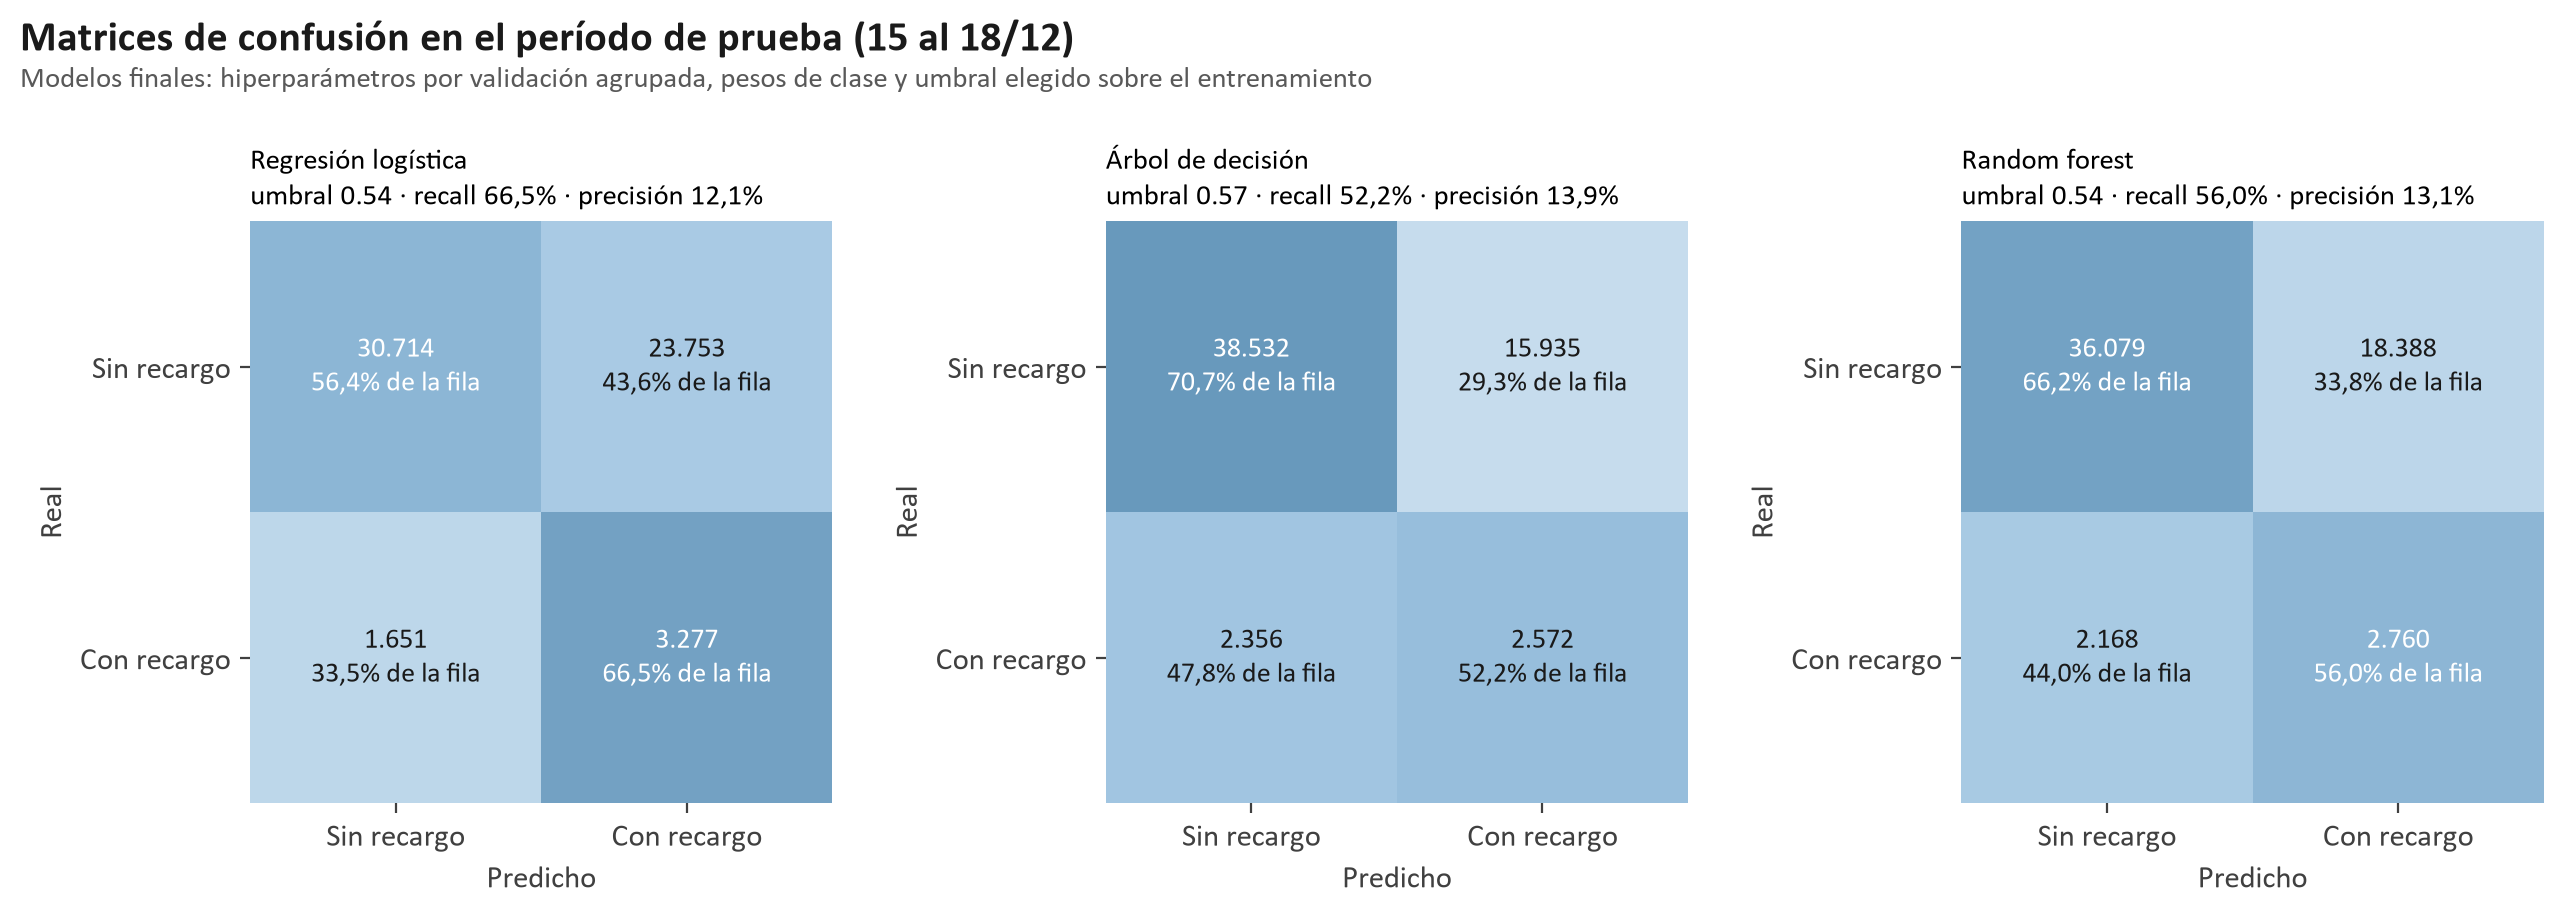

In [14]:
# @title Figura 5 · Matrices de confusión { display-mode: "form" }
figura("fig05_recargo_matrices_confusion.png")

**Elegimos el árbol de decisión** (mejor F1 y PR-AUC, y el más fácil de explicar).

**Cómo leer su accuracy:**

- Accuracy **69,2%**: menor que el 91,7% de "decir siempre que no", porque ahora el modelo **se anima a avisar** recargos y se equivoca en algunos.
- Acierta el **70,7%** de los viajes sin recargo y el **52,2%** de los viajes con recargo → accuracy balanceada **61,5%**, contra 50% de la línea base.
- De cada 100 alertas, **14** son recargos reales (el azar acierta 8).

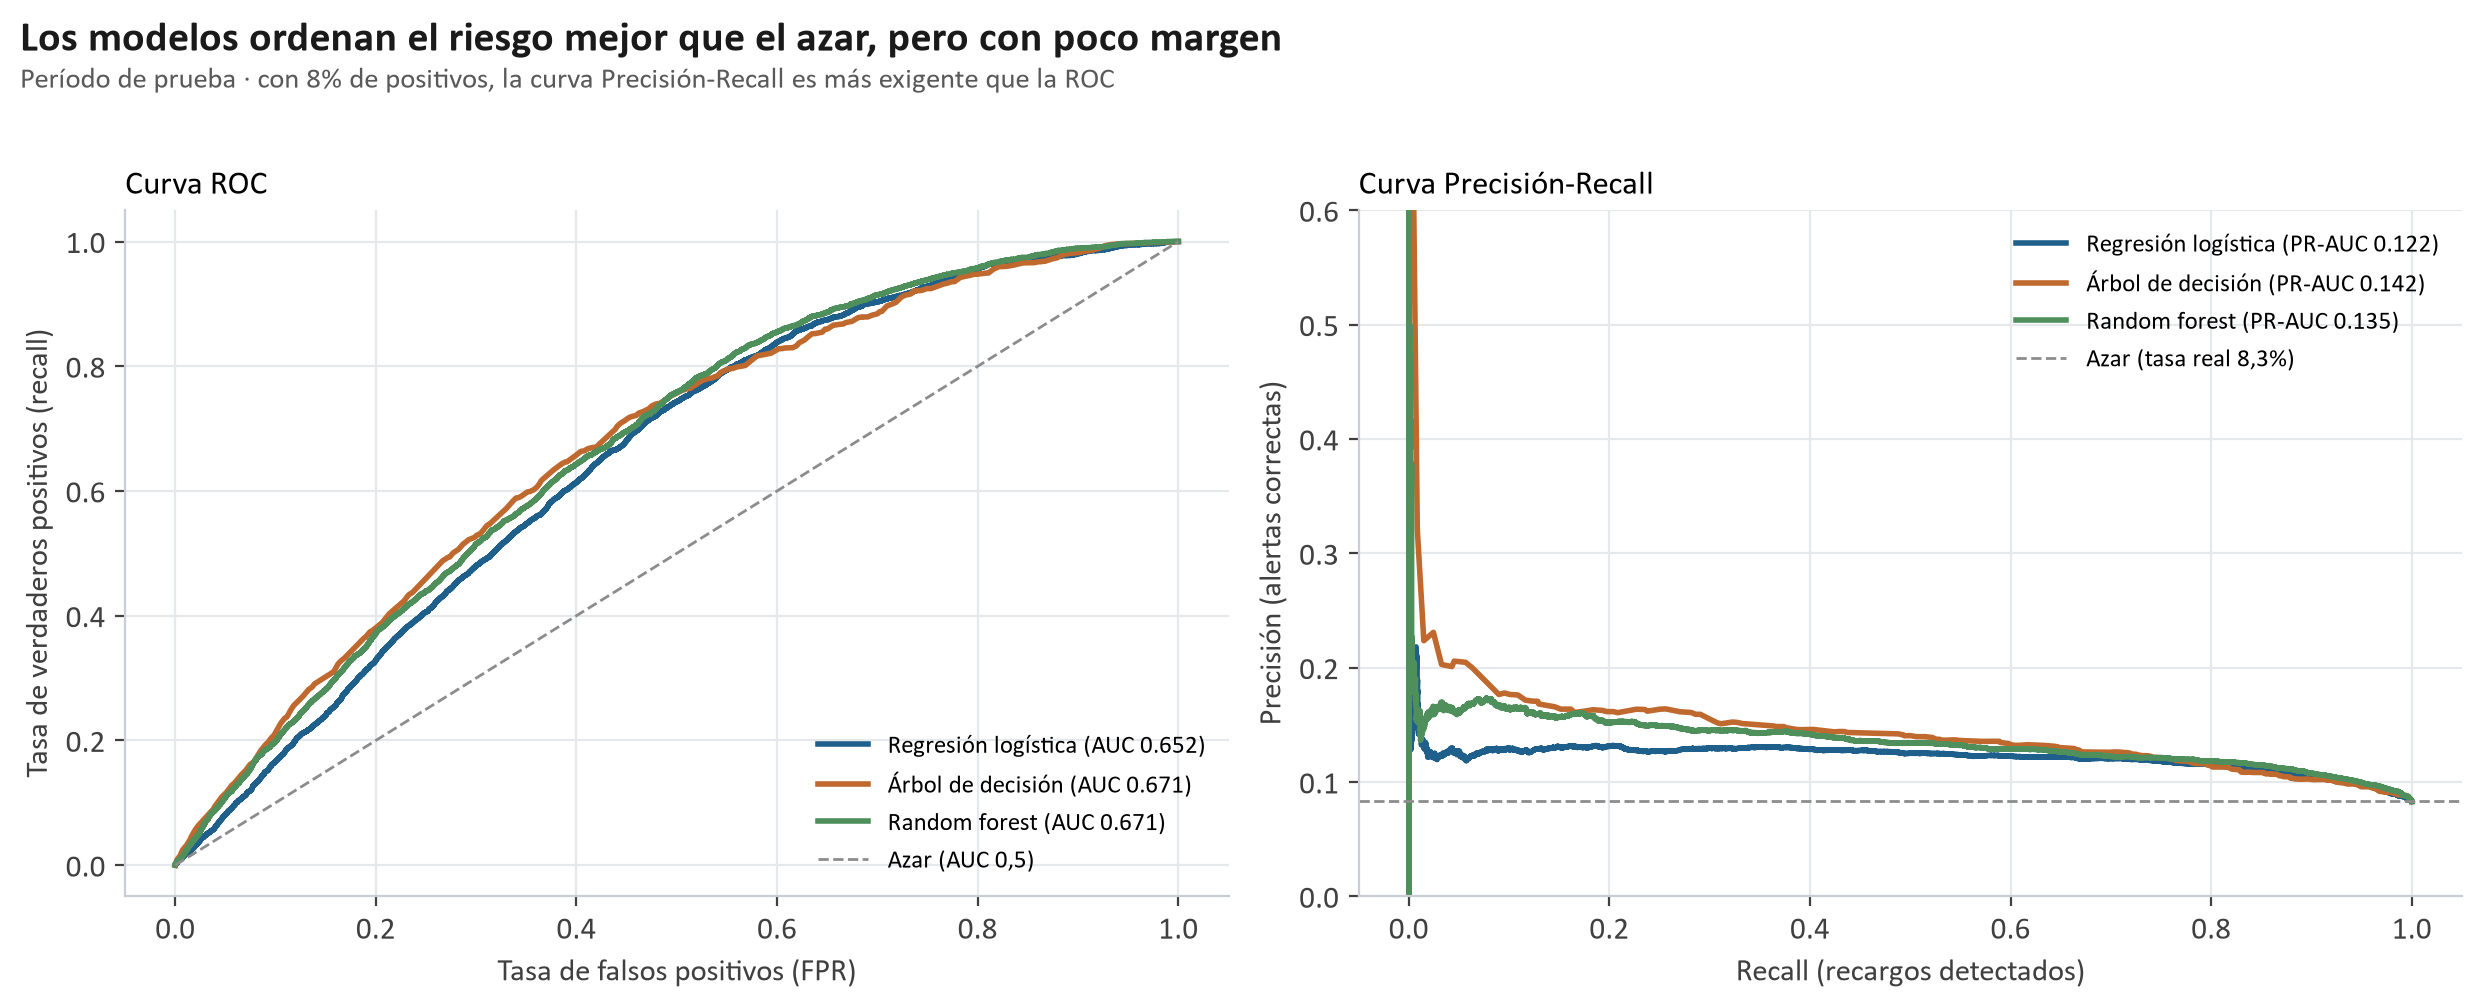

In [15]:
# @title Figura 6 · Curvas ROC y Precisión-Recall { display-mode: "form" }
figura("fig06_recargo_curvas_roc_pr.png")

Los tres modelos están por encima del azar, pero con poco margen (ROC-AUC ≈ 0,67): el recargo es **difícil de anticipar** con los datos disponibles.

## 8 · ¿Qué aprendieron los modelos?

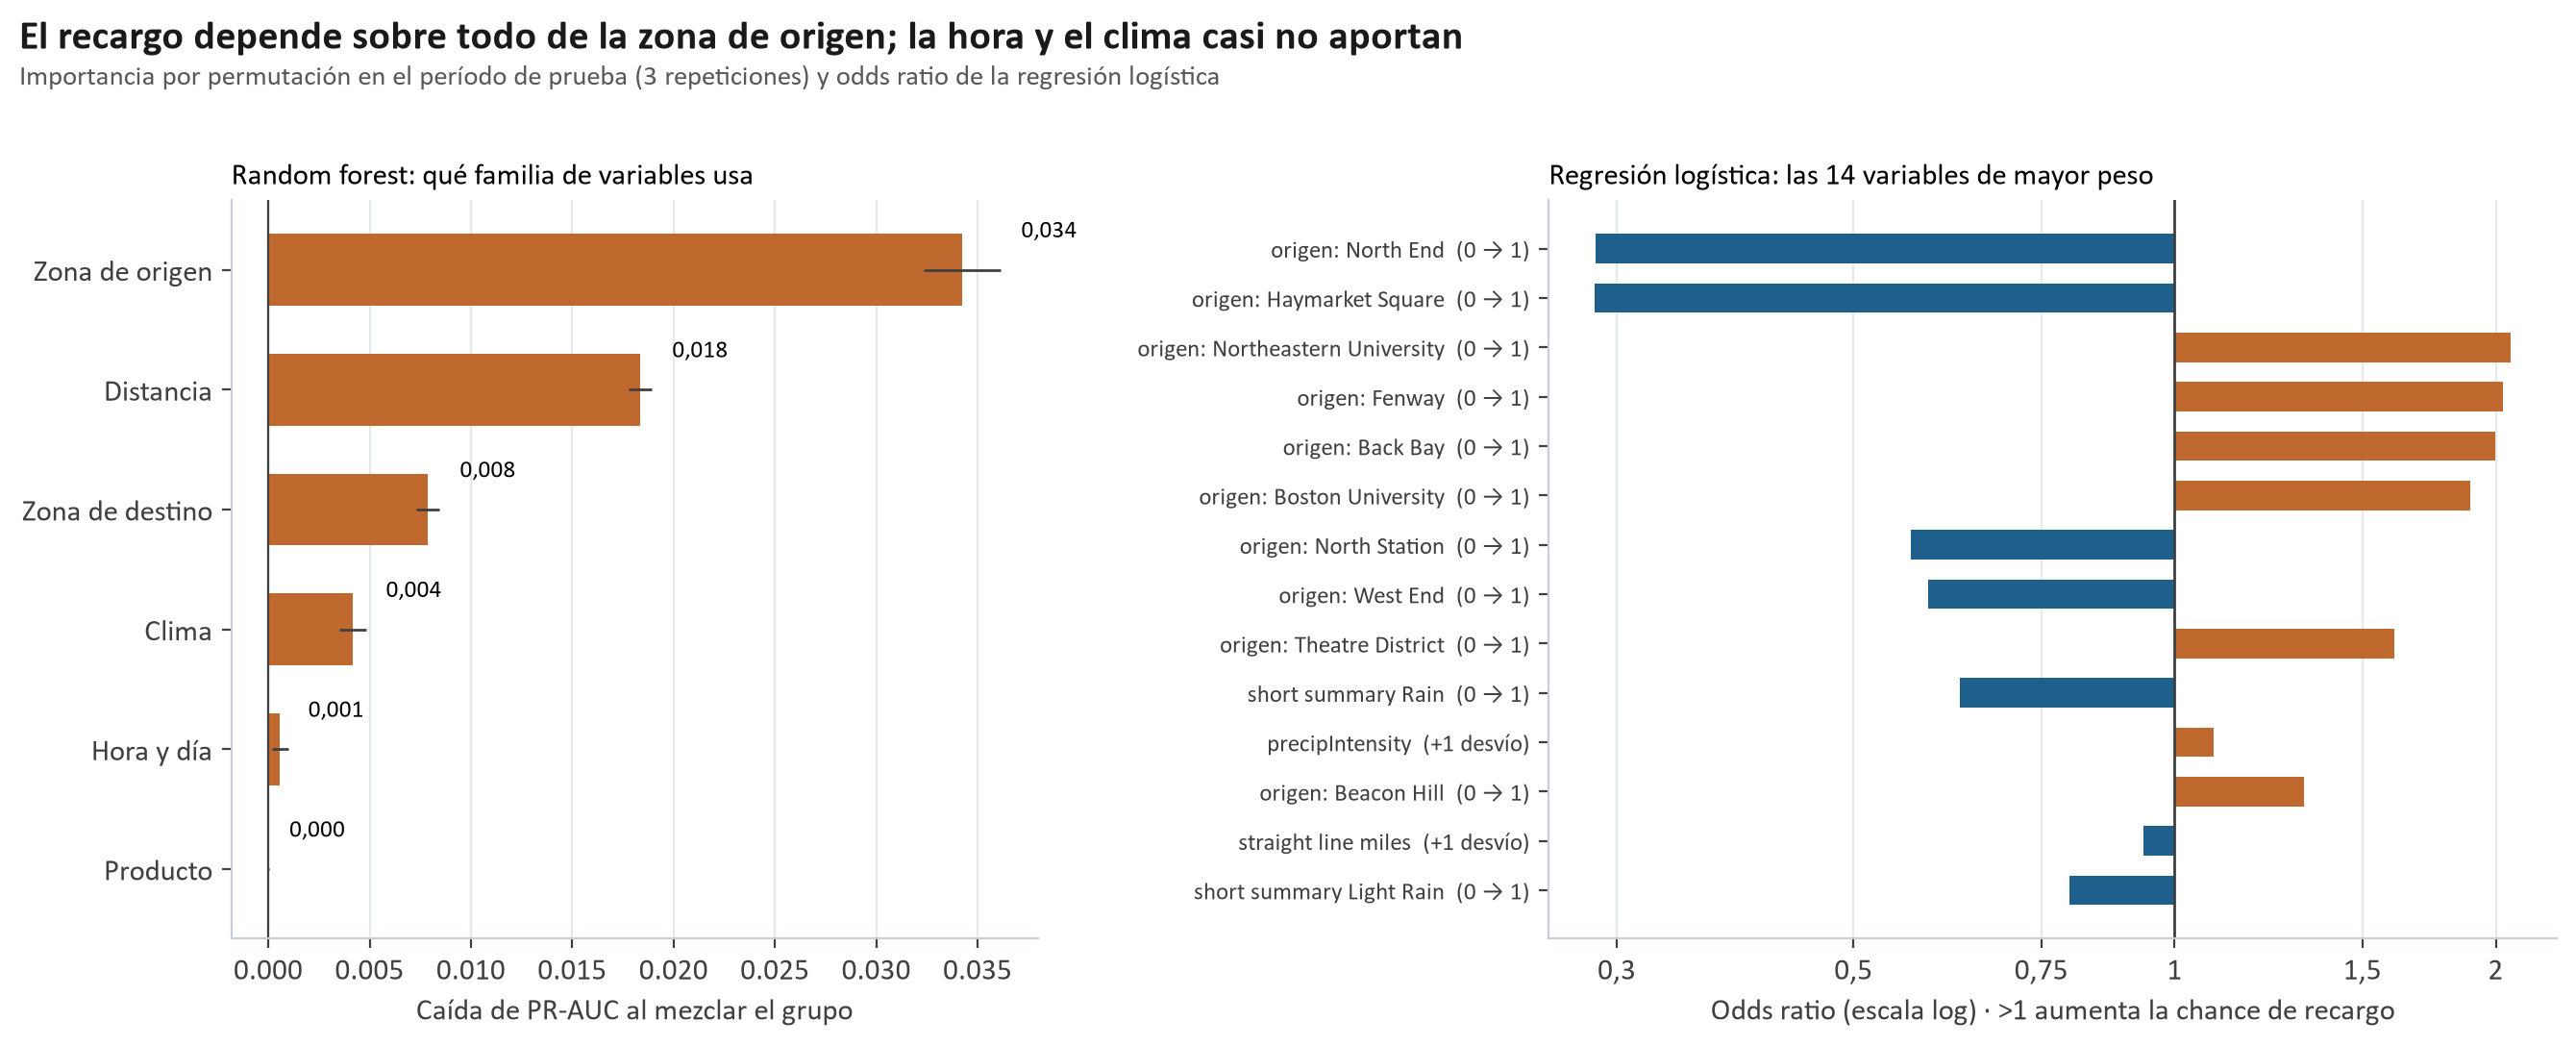

In [16]:
# @title Figura 7 · Importancia de variables y odds ratio { display-mode: "form" }
figura("fig07_recargo_importancia_odds_ratio.png")

- **La zona de origen es lo que más pesa.** Salir de Northeastern University (odds ratio 2,07), Fenway (2,03) o Back Bay (2,00) **duplica la chance de recargo**; salir de North End o Haymarket Square la reduce a menos de un tercio.
- **La hora, el día y el clima casi no aportan** (H3 y H5 no se confirman).

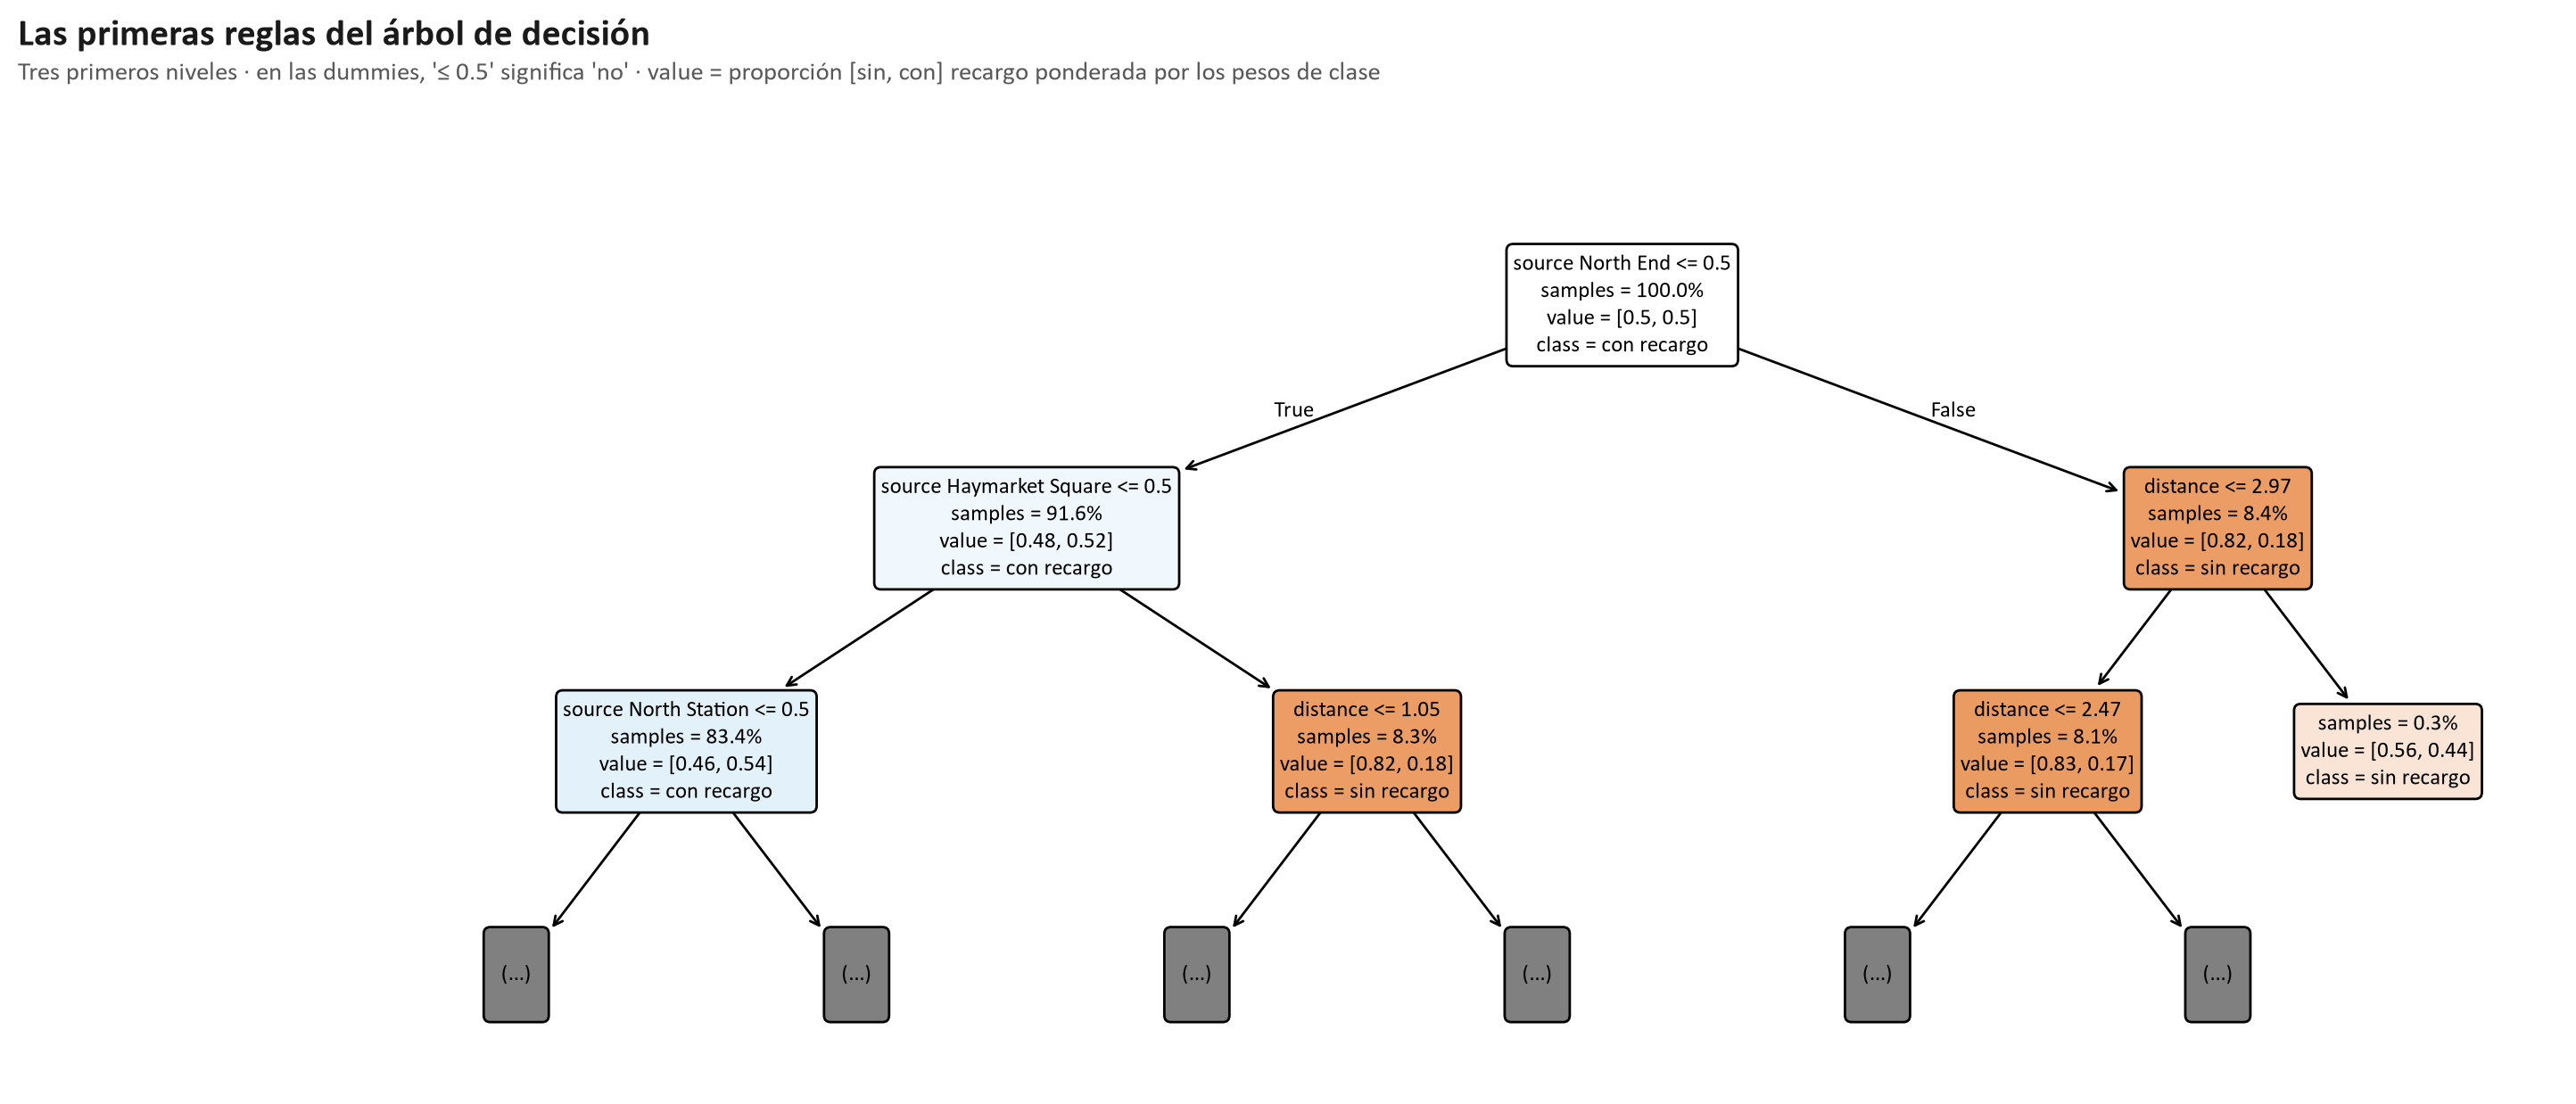

In [17]:
# @title Figura 8 · Las primeras reglas del árbol { display-mode: "form" }
figura("fig08_recargo_arbol_reglas.png")

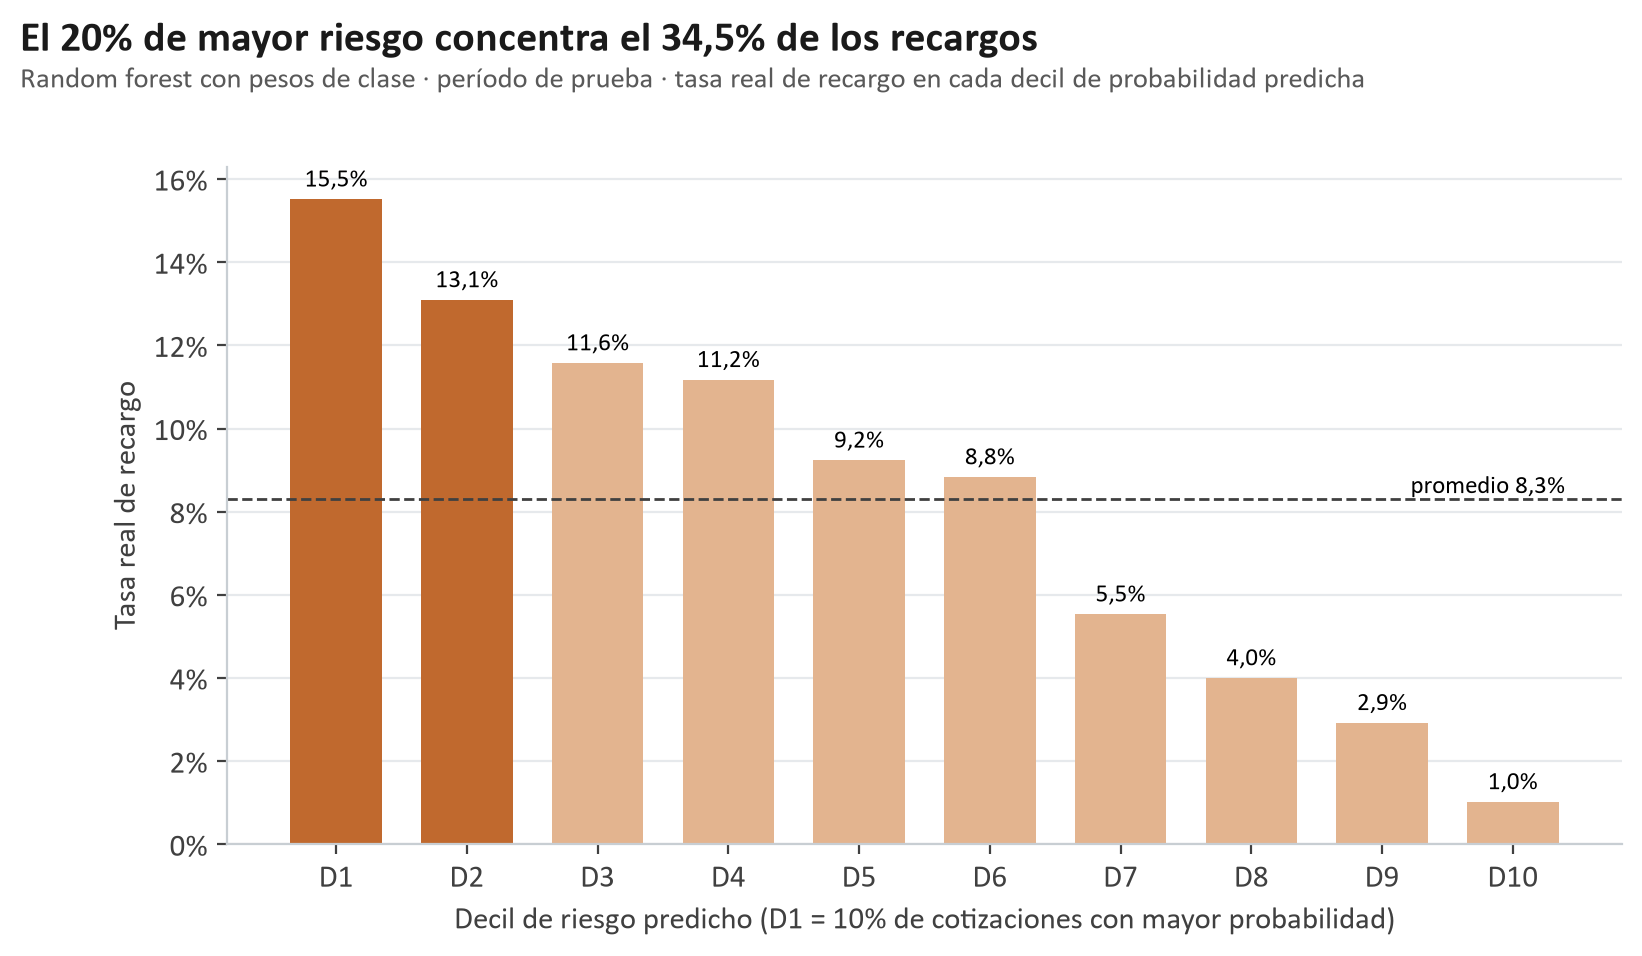

In [18]:
# @title Figura 9 · Uso práctico: deciles de riesgo { display-mode: "form" }
figura("fig09_recargo_deciles_riesgo.png", 850)

El modelo **no adivina** cotización por cotización, pero **ordena el riesgo**: el 10% de mayor riesgo tiene 15,5% de recargos (casi el doble del promedio) y el 20% de mayor riesgo concentra el **34%** de todos los recargos.

## 9 · ¿Por qué validar por fecha?

In [19]:
# @title Partición aleatoria vs partición por fecha { display-mode: "form" }
tabla(pd.DataFrame([[r["modelo"], num(r["roc_auc_aleatoria"]), num(r["roc_auc_temporal"]), num(r["pr_auc_aleatoria"]),
                     num(r["pr_auc_temporal"]), "+" + pct(r["pr_auc_aleatoria"] / r["pr_auc_temporal"] - 1, 0)] for r in M["A_particion"]],
                   columns=["Modelo", "ROC-AUC al azar", "ROC-AUC por fecha", "PR-AUC al azar", "PR-AUC por fecha", "Inflado"]))

Modelo,ROC-AUC al azar,ROC-AUC por fecha,PR-AUC al azar,PR-AUC por fecha,Inflado
Árbol de decisión,"0,706","0,671","0,163","0,142",+15%
Random forest,"0,740","0,671","0,202","0,135",+49%


Con partición aleatoria el random forest parecería un **49% mejor**. Es falso: reconoce cotizaciones del mismo minuto que vio al entrenar.

## 10 · Perfiles de rutas (K-Means)

Agrupamos las 72 rutas por distancia, precio por milla (nivel Estándar) y tasa de recargo. Elegimos **k = 7** por el máximo coeficiente de silueta (0,46); la silueta es casi plana, así que los grupos son una **descripción útil**, no categorías naturales.

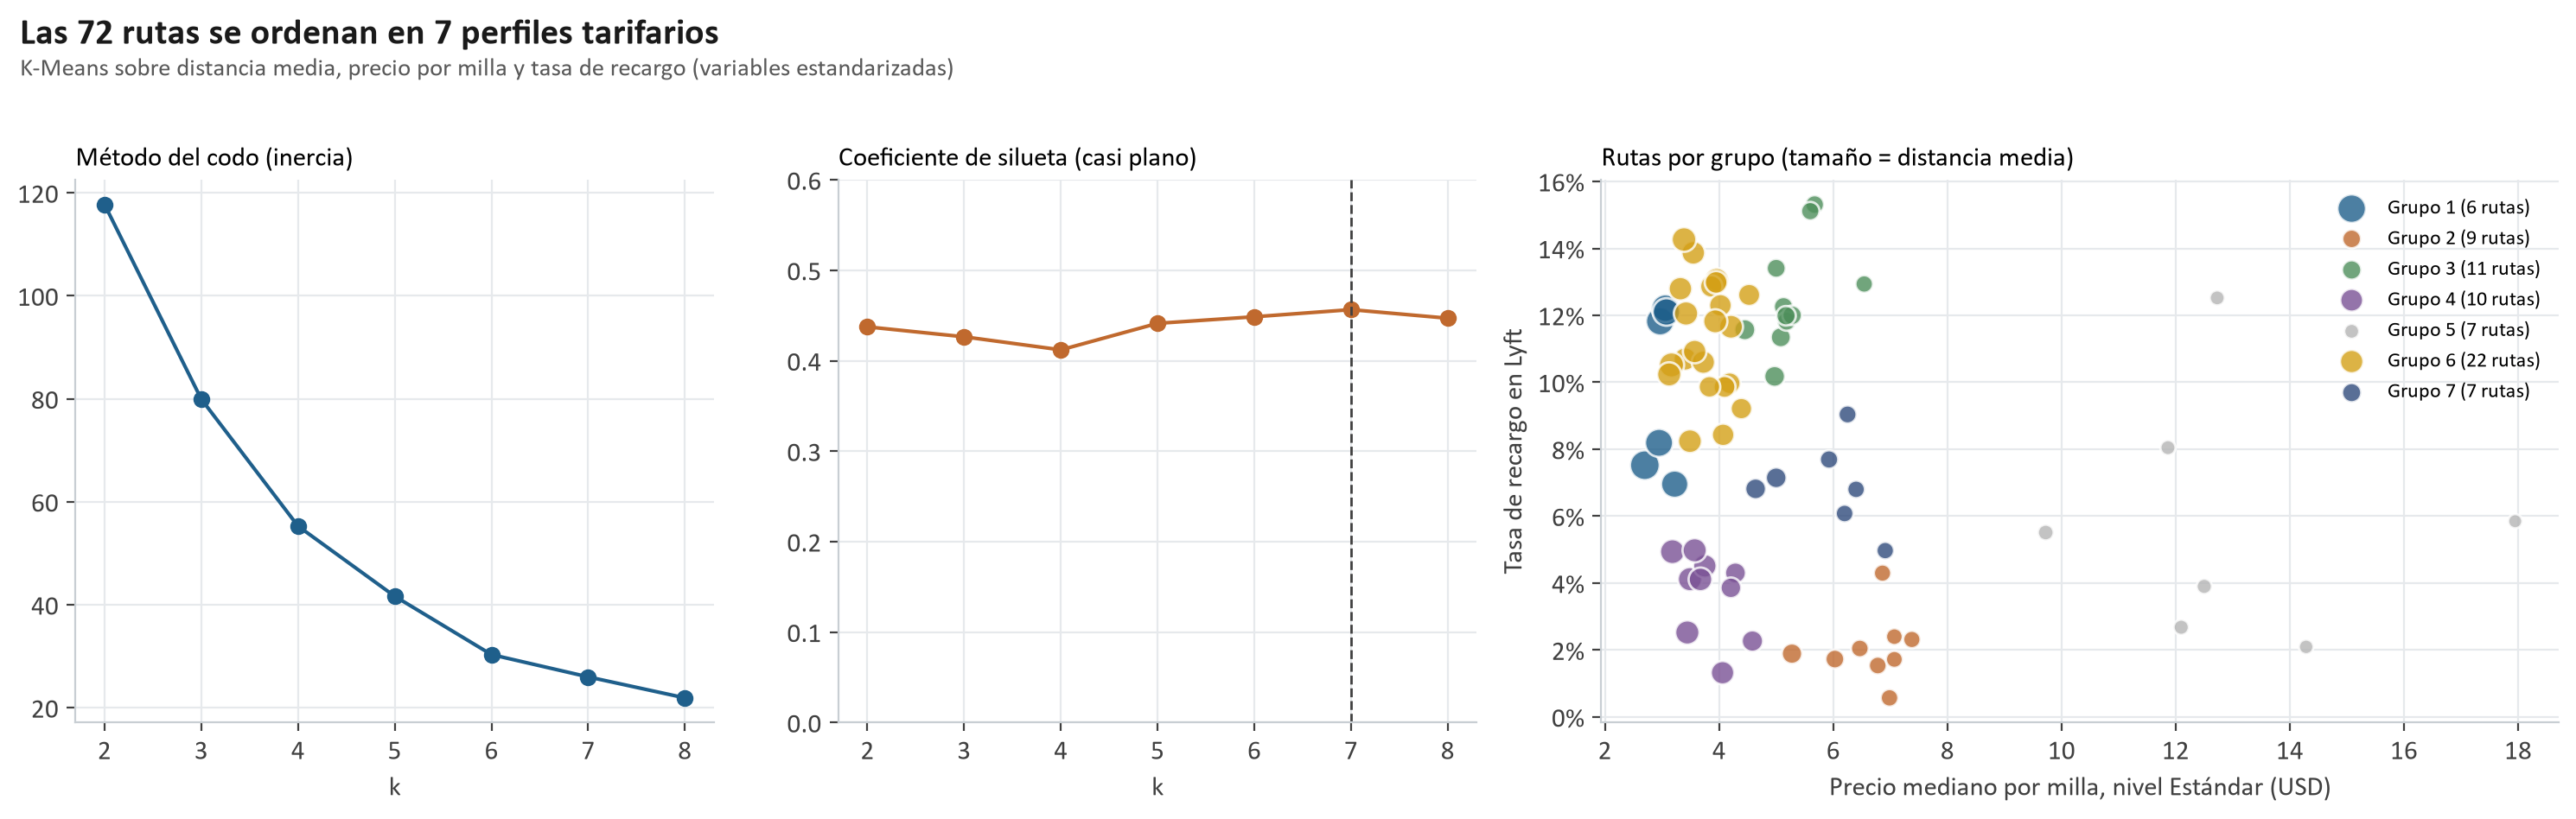

In [20]:
# @title Figura 10 · Codo, silueta y grupos { display-mode: "form" }
figura("fig10_rutas_kmeans.png")

In [21]:
# @title Perfil de cada grupo { display-mode: "form" }
p = pd.read_csv(RES / "rutas_perfil_clusters.csv")
ej = M["C"]["ejemplos"]
tabla(pd.DataFrame({"Grupo": p["cluster"] + 1, "Rutas": p["rutas"], "Distancia media": p["distancia"].map(lambda v: num(v, 2) + " mi"),
                    "Precio por milla": p["precio_milla"].map(usd), "Tasa de recargo": p["tasa_recargo"].map(pct),
                    "Ejemplo": [ej[str(c)][0] for c in p["cluster"]]}))

Grupo,Rutas,Distancia media,Precio por milla,Tasa de recargo,Ejemplo
5,7,"0,59 mi","USD 13,02","5,8%",Theatre District → South Station
2,9,"1,23 mi","USD 6,66","2,1%",North Station → North End
7,7,"1,44 mi","USD 5,90","6,9%",South Station → Theatre District
3,11,"1,61 mi","USD 5,28","12,5%",Back Bay → Boston University
4,10,"2,72 mi","USD 3,82","3,7%",West End → Northeastern University
6,22,"2,75 mi","USD 3,78","11,3%",Northeastern University → North Station
1,6,"4,49 mi","USD 2,99","9,8%",Fenway → Financial District


El precio por milla más alto está en las rutas **muy cortas** (tarifa base, H4) y el recargo se concentra en las rutas que salen de **Back Bay, Fenway y las universidades**, sean cortas o largas.

## 11 · Hipótesis y conclusiones

| Hipótesis | Resultado | Estado |
|---|---|---|
| H1 · Producto y distancia determinan el precio | Dominan la importancia; R² = 0,968 | ✔ Confirmada |
| H2 · Uber y Lyft difieren según el nivel | Lyft más barato en económicos, más caro en Black | ✔ Confirmada |
| H3 · Hay patrones horarios | Hora y día no aportan en ningún modelo | ✘ No se confirma |
| H4 · Hay corredores más caros por milla | Rutas muy cortas: tarifa base | ✔ Confirmada |
| H5 · El mal clima encarece | Sin efecto en precio ni en recargo | ✘ Rechazada |
| H6 · Hay segmentos tarifarios | 7 perfiles de rutas, silueta baja | ≈ Parcial |

### Respuesta al problema

- **El precio es estructural y predecible:** con producto, distancia y multiplicador se estima con un error de ~USD 1,05.
- **El recargo es lo impredecible:** depende del **lugar** de origen, no de la hora ni del clima; el resto depende de la oferta y la demanda en tiempo real, que el dataset no tiene.
- **Valor práctico:** el modelo ordena el riesgo por zona. Si salís de Back Bay, Fenway o las universidades, conviene **comparar con Uber** o caminar a una zona vecina.

### Limitaciones y próximos pasos

- Solo 18 fechas; clima de toda la ciudad por hora; sin datos de oferta/demanda.
- Entrega 4: storytelling para pasajero, conductor y plataforma.

---
### Anexo · Archivos de la entrega

| Carpeta | Contenido |
|---|---|
| `1_Informe/` | Informe en formato paper (`Entrega3_Grupo11.docx`) |
| `2_Presentacion_Colab/` | Esta presentación |
| `3_Codigo/` | `modelado_entrega3.py`: reproduce todos los modelos, gráficos y datasets (~7 min) |
| `4_Datasets/` | Datasets de modelado y datasets balanceados |
| `5_Graficos/` | Figuras (numeradas igual que en el informe) |
| `6_Resultados/` | `metricas.json` y tablas CSV |